# Lab 4 - Kernel Regularized Least Squares

In this lab activity we consider the extension of regularized least squares to non-linear problems using kernel functions.

A brief summary of the tasks:
 1. Generate a simple non-linear data-set
 2. Use **linear** RLS to try and learn with such dataset
 3. Use a **feature transformation** for learning with non-linear data
 4. Implement various kernel functions
 5. Implement kernel RLS
 6. Generate a more complex non-linear data-set
 7. Use kernel RLS for learning on non-linear data, use cross-validation to find the best hyperparameters.

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib as cm
import matplotlib.pyplot as plt
import scipy.linalg
import scipy.spatial
import os

In [ ]:
def calc_err(Ypred, Ytrue):
    return np.mean((Ypred-Ytrue)**2)

# Part 1: Learning with a simple non-linear dataset

## Generate quadratic data

In this lab we are going to use regression datasets where the target `Y` is **not a linear function** of the inputs `X`.

As a first example, see the following function to generate quadratic data.

In [ ]:
def quadratic_data_gen(n, w, sigma_noise):
    # xxx(okachaiev): *advanced* always use np.random.default_rng()
    X = np.random.uniform(-3, 3, size=(n, 1))
    Xsq = X ** 2
    # xxx(okachaiev): *advanced* always use np.random.default_rng()
    noise = np.random.normal(0, sigma_noise, size=(n, 1))

    # Here we can use scalar multiplication since in dimension 1
    Y = Xsq * w + noise

    return X, Y

Shape of x: (100, 1), shape of y: (100, 1)


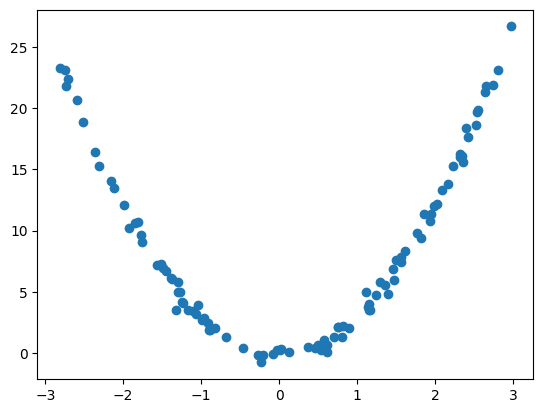

In [ ]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)

print(f"Shape of x: {x_tr.shape}, shape of y: {y_tr.shape}")
fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr);

## Task 1: Linear RLS

The implementation of linear regularized least-squares is given below in the functions `rls_train` and `rls_predict`.

Remember: regularized least-squares has the following form

$$(X_{tr}^\top X_{tr} + \lambda n I)w = X_{tr}^\top Y_{tr}$$


Tasks:
 - Use RLS to train a linear regressor for the quadratic data. Comment on the results.

In [ ]:
def rls_train(x, y, reg_par):
    cov = x.T @ x + reg_par * x.shape[0] * np.eye(x.shape[1])
    rhs = x.T @ y
    w = np.linalg.solve(cov, rhs)
    return w

def rls_predict(x, w):
    return x @ w

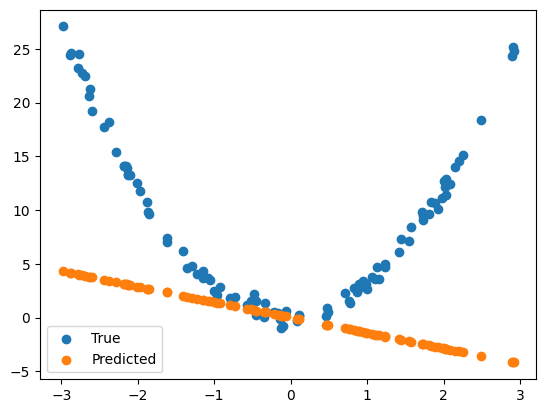

In [ ]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)

# xxx(okachaiev): SOLUTION
w = rls_train(x_tr, y_tr, 0.1)
pred_tr = rls_predict(x_tr, w)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, pred_tr, label="Predicted")
ax.legend(loc="best");

## Task 2: Feature transform

There is a simple way to use a linear algorithm for learning non-linear data: transforming the input data in such a way to convert the problem into a linear one.

This is a simple fix in some cases, but becomes cumbersome if the datasets are non-linear in a complex way.

Here we adopt this approach to train a RLS classifier with the quadratic dataset:
 1. Generate the quadratic dataset
 2. Transform the data so that it becomes a (n, 2) matrix containing the original input, and a transformed version of itself. Clearly the correct transformation depends on the underlying function (a quadratic function!).
 3. Use the RLS algorithm on the new dataset
 4. Plot **and comment** on the results

In [ ]:
# SOLUTION (2)

x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 0.5)

# Instead of just the given xs build a feature matrix with the xs and their squares:
trsf_x_tr = np.concatenate([x_tr, x_tr ** 2], axis=1)

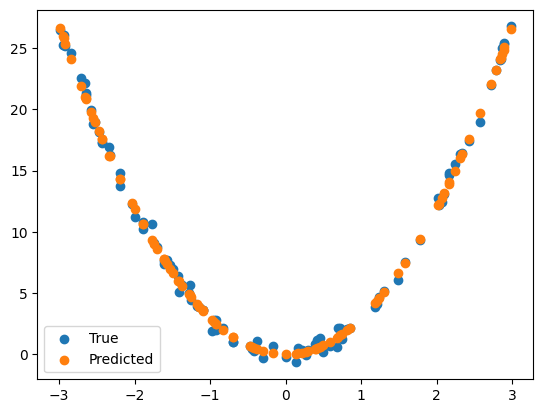

In [ ]:
# SOLUTION (3)

# Now train a linear regression function on the new data!
trsf_w_rls = rls_train(trsf_x_tr, y_tr, 0.1)
pred_tr = rls_predict(trsf_x_tr, trsf_w_rls)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, pred_tr, label="Predicted")
ax.legend(loc="best");

# Part 2: Kernel Least Squares

## Implement 3 types of kernel

The `kernel_matrix` function takes as input two arrays of data, and outputs the kernel matrix evaluated at every pair of points.

You should implement it using the formulas seen in class for the following kernels:
 - linear kernel -- here the `param` argument can be ignored
 - polynomial kernel -- here the `param` argument is the exponent of the kernel
 - gaussian kernel -- here the `param` argument is the kernel length-scale ($\sigma$)

In [ ]:
# xxx(okachaiev): SOLUTION!

def squared_distances(X1, X2):
    """Compute the matrix of pairwise squared-distances between all points in X1 and in X2.
    """
    X1_sqnorm = np.sum(X1**2, axis=1, keepdims=True)
    X2_sqnorm = np.sum(X2**2, axis=1, keepdims=True)
    D_sq = X1_sqnorm + X2_sqnorm.T - 2 * X1 @ X2.T
    np.maximum(D_sq, 0, out=D_sq)
    return D_sq

In [ ]:
# xxx(okachaiev): SOLUTION

def kernel_matrix(X1, X2, kernel_type, param, eps=0.01):
    # X1 : array of shape n x d
    # X2 : array of shape m x d
    X1 = np.atleast_2d(X1)
    X2 = np.atleast_2d(X2)

    # xxx(okachaiev): *advanced* ENUM helps a lot!
    if kernel_type == 'linear':
        return X1 @ X2.T
    elif kernel_type == 'polynomial':
        exponent = param
        return (X1 @ X2.T + eps) ** exponent
    elif kernel_type == 'gaussian':
        lengthscale = param
        sq_dist = squared_distances(X1, X2)
        return np.exp(-sq_dist / (2 * lengthscale**2))
    else:
        raise ValueError(kernel_type)

**Task:** Visualize the kernel (e.g. of the Gaussian type) for random data with different length-scales. What can you observe?

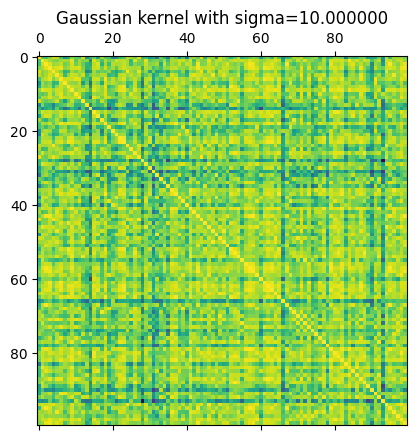

In [ ]:
D = np.random.randn(100, 5) #Creates a random matrix with N(0,1) entries of dimension (100, 5)
lengthscale = 10.
K = kernel_matrix(D, D, "gaussian", lengthscale)
fig, ax = plt.subplots()
ax.matshow(K)
ax.set_title("Gaussian kernel with sigma=%f" % (lengthscale));

## Implement Kernel RLS

Remember that, given kernel $K = k(x_i, x_j)$ for $i=(1, \dots, n)$ and $j=(1, \dots, n)$, KRLS learns a weight-vector with the following formula

$$(K + n \lambda I)w = Y$$

and then predictions on some new point $\tilde{x}$ are given by

$$f^{\mathrm{KRLS}}(\tilde{x}) = k(\tilde{x}, X^{\mathrm{train}}) w$$

In [ ]:
def krls_train(x, y, reg_par, kernel_type, kernel_par):
    n, D = x.shape
    # xxx(okachaiev): solution
    K = kernel_matrix(x, x, kernel_type, kernel_par)
    lhs = K + n * reg_par * np.eye(n)
    w = np.linalg.solve(lhs, y)
    return w

def krls_predict(x_test, x_tr, w, kernel_type, kernel_par):
    # xxx(okachaiev): solution
    K = kernel_matrix(x_test, x_tr, kernel_type, kernel_par)
    y_pred = K @ w
    return y_pred

Now test the functions you have implemented on the quadratic dataset.

**Tasks:**
 1. use the linear kernel, can you fit the data?
 2. use the polynomial kernel, test the effect of the kernel parameter on the results:
    - describe what happens with a low/high exponent in terms of the bias-variance tradeoff.
 3. use the polynomial kernel, but fix the kernel parameter. Test the effect of the regularization parameter
    - describe what happens with a low/high regularizer in terms of the bias-variance tradeoff

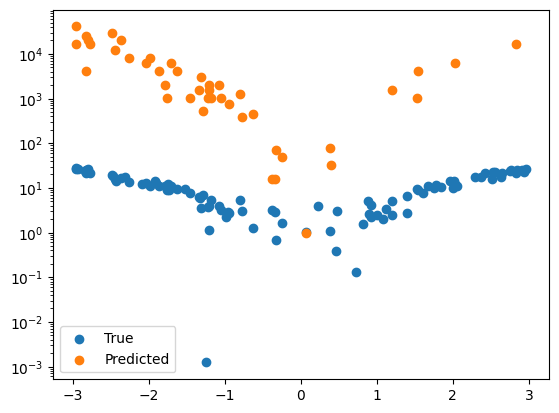

In [ ]:
x_tr, y_tr = quadratic_data_gen(100, np.array([3]), 2.0)

ker_par = 3.0
reg_param = 1e-9

# xxx(okachaiev): solution
ker_type = "polynomial"
w_krls = krls_train(x_tr, y_tr, 0., ker_type, ker_par)
ypred_tr = krls_predict(x_tr, x_tr, w_krls, ker_type, ker_par)

fig, ax = plt.subplots()
ax.scatter(x_tr, y_tr, label="True")
ax.scatter(x_tr, ypred_tr, label="Predicted")
# xxx(okachaiev): switching to log scale!
ax.set_yscale('log')
ax.legend(loc="best");

## Generating a more complex non-linear dataset

Define a function to generate a d-dimensional synthetic dataset where the targets `Y` depend non-linearly on the variables `X`.

The parameters of the function are:
 - n : the number of samples
 - d : the dimension of the samples
 - low_d : the lower-bound for the uniformly distributed samples
 - high_d : the higher-bound for the uniformly distributed samples
 - sigma_noise : standard deviation of Gaussian noise added to the targets

It should return:
 - X : 2D array of size n, d which fits in the desired bounds
 - Y : 2D array of size n, 1 which is a non-linear function of `X` (and a linear function of `w`)

Examples of non-linear regression functions:
 - polynomial dependence of the Y on the X data
 - logarithmic dependence
 - more complex transforms (e.g. trig functions)


In [ ]:
def nonlinear_data_gen(n, d, low_d, high_d, sigma_noise):
    X = np.random.uniform(low=low_d, high=high_d, size=(n, d))

    Y = X ** d # but try with other options!

    # Add noise
    noise = np.random.normal(0, sigma_noise, size=(n, 1))
    Y_noisy = Y + noise

    return X, Y_noisy

## KRLS and cross-validation
Now we will use KRLS and k-fold CV to learn on the complex non-linear datasets we have generated.

In this last part you will have to do the following:
 1. Generate a non-linear dataset, find the best hyperparameters (using e.g. the Gaussian kernel) with the training set, and then use them to make predictions on the test-set. Are you able to fit your data well?
 2. Analyse how the amount of noise (see the `sigma_noise` parameter of `nonlinear_data_gen`) influences the best lambda as selected by cross-validation. In particular answer to the following question:
     - How does the best lambda change as you increase/decrease the amount of noise in your dataset? Why?
     
    **Hint: keep the kernel parameter fixed for this third task, otherwise it might be very hard to see**

In [ ]:
def krls_kfold_valerr(x_tr, y_tr, num_folds, reg_par, kernel_type, kernel_par):
    """
    Compute the k-fold cross-validation error for one KRLS model (with speficied regularization,
    kernel and kernel parameter).

    This function returns both the training errors and the validation errors
    obtained from CV (as numpy arrays).
    """
    if num_folds <= 1:
        raise Exception("Please supply a number of folds > 1")

    n_tot = x_tr.shape[0]
    n_val = int(n_tot // num_folds) # // performs the floor division, outputs a float

    tr_errs, val_errs = [], []
    # `split_idx`: a list of arrays, each containing the validation indices for 1 fold
    rand_idx = np.random.choice(n_tot, size=n_tot, replace=False)
    split_idx = np.array_split(rand_idx, num_folds)
    for fold in range(num_folds):
        # Set the indices in boolean mask for all validation samples to `True`
        val_mask = np.zeros(n_tot, dtype=bool)
        val_mask[split_idx[fold]] = True

        kf_x_tr = x_tr[~val_mask]
        kf_y_tr = y_tr[~val_mask]
        kf_x_val = x_tr[val_mask]
        kf_y_val = y_tr[val_mask]

        w_krls = krls_train(kf_x_tr, kf_y_tr, reg_par=reg_par, kernel_type=kernel_type, kernel_par=kernel_par)

        pred_val = krls_predict(kf_x_val, kf_x_tr, w_krls, kernel_type=kernel_type, kernel_par=kernel_par)
        val_errs.append(calc_err(pred_val, kf_y_val))
    return np.mean(np.asarray(val_errs))

In [ ]:
def krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, kernel_type, kernel_par_list):
    """Choose the best parameters for both the regularizer and the kernel parameter according to K-Fold CV.
    """
    errors = np.zeros((len(reg_par_list), len(kernel_par_list)))
    for i, reg_par in enumerate(reg_par_list):
        for j, kernel_par in enumerate(kernel_par_list):
            errors[i, j] = krls_kfold_valerr(x_tr, y_tr, num_folds, reg_par, kernel_type, kernel_par)

    best_reg_par = reg_par_list[np.unravel_index(np.argmin(errors), errors.shape)[0]]
    best_kernel_par = kernel_par_list[np.unravel_index(np.argmin(errors), errors.shape)[1]]
    best_err = np.min(errors)
    print(f"The best error (MSE={best_err*100:.2f}%) was obtained with "
          f"lambda={best_reg_par}, kernel_parameter={best_kernel_par}")
    return best_reg_par, best_kernel_par, best_err

In [ ]:
# Data gen parameters

n_tr = 200
n_test = 100
d = 1
low_d = -2
high_d = 2
sigma_noise = 0.1

x_tr, y_tr = nonlinear_data_gen(n_tr, d, low_d, high_d, sigma_noise)
x_test, y_test = nonlinear_data_gen(n_test, d, low_d, high_d, sigma_noise)

# K_fold parameters
num_folds = 5
reg_par_list = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1., 10., 50., 100., 500.]
ker_type = 'gaussian'
# ker_par_list = [0.01 * (10**i) for i in range(5)]
ker_par_list = [1.]

# Compute HERE the best kernel parameter and the best regularization parameter (use krls_kfoldcv!)
# xxx(okachaiev): solution
best_reg_par, best_kernel_par, _ = krls_kfoldcv(
    x_tr, y_tr, num_folds, reg_par_list, ker_type, ker_par_list)

# Now retrain on the whole of x_tr with the best parameters and test on x_ts!
w_krls = krls_train(x_tr, y_tr, best_reg_par, "gaussian", best_kernel_par)
y_pred = krls_predict(x_test, x_tr, w_krls, "gaussian", best_kernel_par)
test_error = calc_err(y_pred, y_test)
# xxx(okachaiev): why is it in percentage? if it's MSE
print(f'The MSE on the test data is: {test_error*100:.2f}%')

The best error (MSE=0.92%) was obtained with lambda=1e-05, kernel_parameter=1.0
The MSE on the test data is: 1.04%


In [ ]:
# TODO: Analyse the effect of noise!

for noise in [0.001, 0.01, 0.1, 0.2, 0.5]:
    print('-------------------------------------------------------------------------')
    print(f'Noise {noise}:')
    x_tr, y_tr = nonlinear_data_gen(n_tr, d, low_d, high_d, noise)
    x_test, y_test = nonlinear_data_gen(n_test, d, low_d, high_d, noise)

    best_reg_par, best_kernel_par, _ = krls_kfoldcv(x_tr, y_tr, num_folds, reg_par_list, ker_type, ker_par_list)

    # Now retrain on the whole of x_tr with the best parameters and test on x_ts!
    w_krls = krls_train(x_tr, y_tr, reg_par=best_reg_par, kernel_type=ker_type, kernel_par=best_kernel_par)
    y_pred = krls_predict(x_test, x_tr, w_krls, kernel_type=ker_type, kernel_par=best_kernel_par)
    test_error = calc_err(y_pred, y_test)
    print(f'The MSE on the test data is: {test_error*100:.2f}%\n')

-------------------------------------------------------------------------
Noise 0.001:
The best error (MSE=0.00%) was obtained with lambda=1e-06, kernel_parameter=1.0
The MSE on the test data is: 0.00%

-------------------------------------------------------------------------
Noise 0.01:
The best error (MSE=0.01%) was obtained with lambda=1e-06, kernel_parameter=1.0
The MSE on the test data is: 0.01%

-------------------------------------------------------------------------
Noise 0.1:
The best error (MSE=1.15%) was obtained with lambda=1e-06, kernel_parameter=1.0
The MSE on the test data is: 1.25%

-------------------------------------------------------------------------
Noise 0.2:
The best error (MSE=4.23%) was obtained with lambda=0.001, kernel_parameter=1.0
The MSE on the test data is: 2.85%

-------------------------------------------------------------------------
Noise 0.5:
The best error (MSE=23.26%) was obtained with lambda=1e-05, kernel_parameter=1.0
The MSE on the test data is

# Bias-Variance Trade-off Sensitivity Study

In this task, you will investigate how the regularization parameter (λ) in the Kernel Regularized Least Squares (KRLS) model affects the bias and variance of the predictions.

**Steps:**
1. **Data Generation:**  
   Use the provided data generation routines to obtain training and test datasets. The true underlying function is known, and noise is added to simulate realistic conditions.

2. **Model Training:**  
   For each value of λ (regularization parameter) in a predefined grid, train the KRLS model multiple times (using different random training samples or bootstrap samples).

3. **Bias & Variance Estimation:**  
   - For each test point, compute the average prediction over repeated experiments.  
   - **Bias^2:** Estimate as the squared difference between the average prediction and the true function value.  
   - **Variance:** Estimate as the variability (variance) of the predictions across experiments.
   - Compute the overall mean squared error (MSE) as the total error.

4. **Visualization:**  
   Plot the estimated bias^2, variance, and total error as a function of λ (using a logarithmic scale for λ). Analyze the plots to identify the region where the bias-variance trade-off is optimized.

Use the following cell to run the experiments and generate the plots.

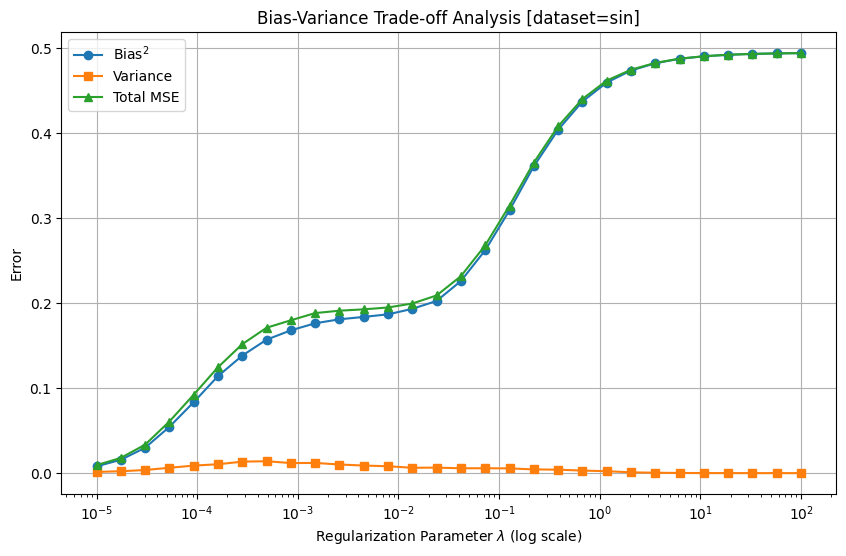

In [ ]:
def true_function(x):
    return np.sin(2 * np.pi * x)


# dataset generators return both noiseless and noisy targets
def generate_train_data(dataset, n_samples=50, noise_std=0.1):
    if dataset == 'sin':
        X = np.sort(np.random.rand(n_samples))
        y_true = true_function(X)
        y = y_true + np.random.normal(0, noise_std, size=n_samples)
        return X.reshape(-1, 1), y.reshape(-1, 1), y_true.reshape(-1, 1)
    elif dataset == 'polynomial':
        return _nonlinear_data_gen(n_samples=n_samples, noise_std=noise_std)
    else:
        raise ValueError(f"Unknown dataset: {dataset}")


def generate_test_data(dataset, n_samples=100, noise_std=0.1):
    if dataset == 'sin':
        X = np.linspace(0, 1, n_samples)
        y_true = true_function(X)
        y = y_true + np.random.normal(0, noise_std, size=n_samples)
        return X.reshape(-1, 1), y.reshape(-1, 1), y_true.reshape(-1, 1)
    elif dataset == 'polynomial':
        return _nonlinear_data_gen(n_samples=n_samples, noise_std=noise_std)
    else:
        raise ValueError(f"Unknown dataset: {dataset}")


# previosly used datasets
def _nonlinear_data_gen(n_samples, d=1, low_d=-2, high_d=2, noise_std=0.1):
    X = np.random.uniform(low=low_d, high=high_d, size=(n_samples, d))
    Y = X ** d
    noise = np.random.normal(0, noise_std, size=(n_samples, 1))
    return X, Y + noise, Y


# parameters for the sensitivity study
dataset = 'sin'   # type of data generation function to use ('sin' or 'polynomial')
n_experiments = 250      # number of experiments for each lambda value
n_train = 50             # training set size
n_test = 100             # test set size
noise_std = 0.1          # noise level in data
lambda_values = np.logspace(-5, 2, num=30)  # Rregularization parameters $\lambda$ grid
kernel = 'gaussian'
gamma = 1.0

# generate a fixed test set (assumed to be noise-free evaluations of the true function with added noise)
X_test, y_test, true_y_test = generate_test_data(dataset, n_samples=n_test, noise_std=noise_std)

# for storing error components for each lambda value
bias_sq_hist = np.zeros(len(lambda_values))
variance_hist = np.zeros(len(lambda_values))
total_error_hist = np.zeros(len(lambda_values))

# loop over each lambda value
for lam_id, lam in enumerate(lambda_values):
    # collect predictions from multiple experiments for the current lambda
    all_predictions = np.zeros((n_experiments, n_test, 1))

    for exp in range(n_experiments):
        # generate a new training set for each experiment
        X_train, y_train, _ = generate_train_data(dataset, n_samples=n_train, noise_std=noise_std)

        # get predictions on the test set using KRLS
        w_krls = krls_train(X_train, y_train, lam, kernel, gamma)
        all_predictions[exp, :] = krls_predict(X_test, X_train, w_krls, kernel, gamma)

    # average prediction for each test point over all experiments
    avg_predictions = np.mean(all_predictions, axis=0)
    # bias^2: mean squared difference between the average prediction and the true function values
    bias_sq = np.mean((avg_predictions - true_y_test) ** 2)
    # variance: average of the variances (across experiments) of predictions for each test point
    variance = np.mean(np.var(all_predictions, axis=0))
    # total error: average MSE over experiments (this includes bias, variance, and noise)
    total_mse = np.mean((all_predictions - true_y_test) ** 2)

    bias_sq_hist[lam_id] = bias_sq
    variance_hist[lam_id] = variance
    total_error_hist[lam_id] = total_mse


# plot the Bias^2, Variance, and Total Error against lambda values (logarithmic scale for lambda)
plt.figure(figsize=(10, 6))
plt.semilogx(lambda_values, bias_sq_hist, marker='o', label='Bias$^2$')
plt.semilogx(lambda_values, variance_hist, marker='s', label='Variance')
plt.semilogx(lambda_values, total_error_hist, marker='^', label='Total MSE')
plt.xlabel('Regularization Parameter $\lambda$ (log scale)')
plt.ylabel('Error')
plt.title(f'Bias-Variance Trade-off Analysis [dataset={dataset}]')
plt.legend()
plt.grid(True)
plt.show()

# Two-Dimensional Parameter Grid: Regularization and Kernel Parameters

In this task, you will explore how both the regularization parameter (λ) and the kernel parameter (e.g., the Gaussians kernel's bandwidth) affect the performance of the KRLS model. You will build a two-dimensional grid over these parameters, run multiple experiments for each grid point, and then plot a contour map of the average mean squared error (MSE) on a fixed test set.

**Steps:**
1. **Data Setup:**  
   - Use a fixed test set generated with your data generation routine.
   - Generate a new training set for each experiment to account for randomness.

2. **Parameter Grid:**  
   - Define a logarithmically spaced grid for both the regularization parameter (λ) and the kernel parameter (gamma).
   - For each (λ, gamma) pair, run multiple experiments to compute the average test error (MSE).

3. **Error Aggregation:**  
   - For each grid point, compute the average MSE over several experiments.

4. **Contour Plot:**  
   - Create a contour plot showing the relationship between (λ, gamma) and the test error.
   - Use logarithmic scales for the parameter axes to better capture the grid dynamics.

Run the next cell to execute the experiments and visualize the contour plot.

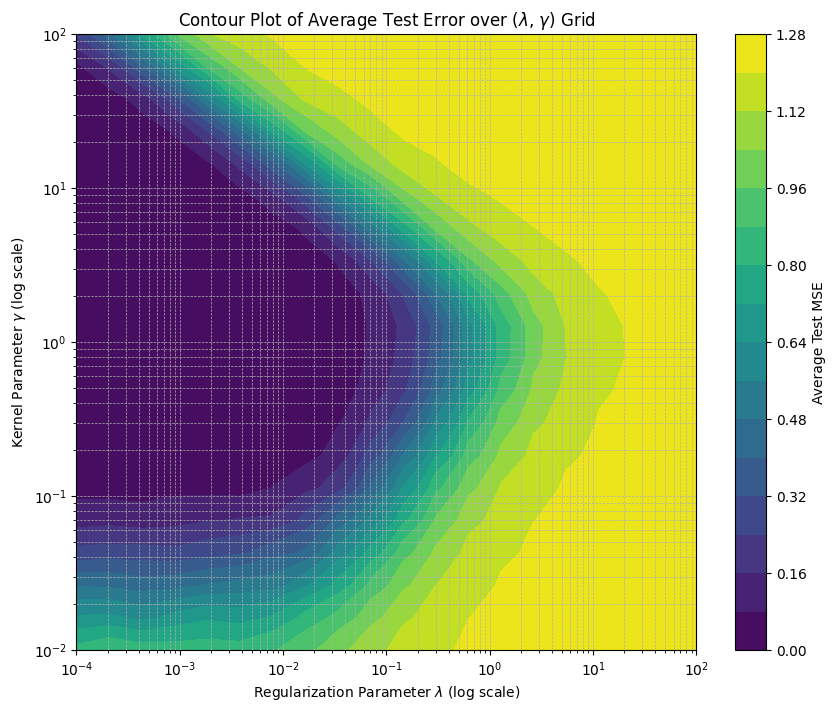

In [ ]:
# parameters for the experiments
dataset = 'polynomial'   # dataset generating function ('sin' or 'polynomial')
n_experiments = 20       # number of experiments per grid point
n_train = 50             # training set size
n_test = 100             # test set size
noise_std = 0.1          # noise level

# define parameter grids (log spaced)
lambda_values = np.logspace(-4, 2, num=20)  # regularization parameter grid (λ)
gamma_values = np.logspace(-2, 2, num=20)   # kernel parameter grid (gamma for Gaussian kernel)

# generate a fixed test set
X_test, y_test, true_y_test = generate_test_data(dataset, n_samples=n_test, noise_std=noise_std)

# prepare an array to store the average MSE for each (λ, gamma) pair.
# use a grid where rows correspond to gamma and columns to lambda.
error_grid = np.zeros((len(gamma_values), len(lambda_values)))

# loop over gamma and lambda values to compute average test error for each grid point
for j, gamma in enumerate(gamma_values):
    for i, lam in enumerate(lambda_values):
        errors = np.zeros(n_experiments)
        for exp in range(n_experiments):
            # generate a new training set for each experiment
            X_train, y_train, _ = generate_train_data(dataset, n_samples=n_train, noise_std=noise_std)

            # predictions from the KRLS model with current parameters
            w_krls = krls_train(X_train, y_train, lam, 'gaussian', gamma)
            y_pred = krls_predict(X_test, X_train, w_krls, 'gaussian', gamma)

            # compute mean squared error for this experiment
            errors[exp] = np.mean((y_pred - true_y_test) ** 2)

        # store the average MSE for the current parameter combination.
        error_grid[j, i] = np.mean(errors)

# create a meshgrid for contour plotting
Lambda, Gamma = np.meshgrid(lambda_values, gamma_values)

# plot the contour map of average test error
plt.figure(figsize=(10, 8))
contour = plt.contourf(Lambda, Gamma, error_grid, 20, cmap='viridis')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Regularization Parameter $\lambda$ (log scale)')
plt.ylabel('Kernel Parameter $\gamma$ (log scale)')
plt.title('Contour Plot of Average Test Error over ($\lambda$, $\gamma$) Grid')
plt.colorbar(contour, label='Average Test MSE')
plt.grid(True, which='both', ls='--', lw=0.5)
plt.show()

# Feature Space Visualization with Kernel PCA

In this task, you will use kernel PCA to visualize the data in the high-dimensional feature space induced by your kernel. Kernel PCA projects data into the principal component directions defined by the eigen-decomposition of the centered kernel matrix. This provides insights into how the kernel transformation reveals structure in the data.

**Steps:**
1. **Kernel Matrix Computation:**  
   Use the provided method to compute the kernel matrix for your dataset using a chosen kernel (e.g., RBF).  
2. **Centering the Kernel Matrix:**  
   Center the kernel matrix to ensure that the data is zero-mean in the feature space.  
3. **Eigen-decomposition:**  
   Compute the eigenvalues and eigenvectors of the centered kernel matrix.  
4. **Projection and Visualization:**  
   Select the top principal components (typically the first two) and project your data onto these axes.  
   Visualize the resulting 2D projection, optionally coloring points based on their target values to reveal patterns or clusters.

Use the next cell to run the experiment and generate the feature space visualization.

Percentage of explained variance by the first 2 principal components: 89.07%


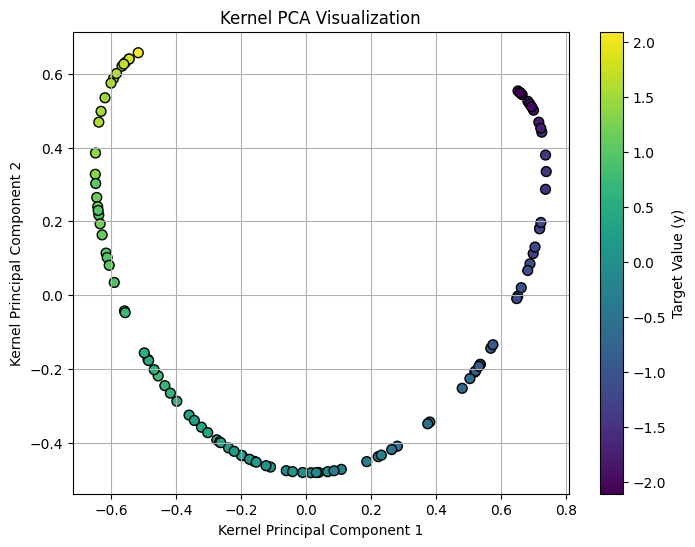

In [ ]:
def center_kernel_matrix(K):
    n = K.shape[0]
    one_n = np.ones((n, n)) / n
    return K - one_n @ K - K @ one_n + one_n @ K @ one_n


# generate data (using training data as an example)
X_data, y_data, _ = generate_train_data('polynomial', n_samples=100, noise_std=0.1)

# compute the kernel matrix using the provided function
K = kernel_matrix(X_data, X_data, kernel_type='gaussian', param=1.0)

# center the kernel matrix
K_centered = center_kernel_matrix(K)

# compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(K_centered)

# select the top 2 principal components for visualization.
# scale by the square root of their corresponding eigenvalues
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
PC1 = eigenvectors[:, 0] * np.sqrt(eigenvalues[0])
PC2 = eigenvectors[:, 1] * np.sqrt(eigenvalues[1])

# report percentage of explained variance by the top 2 principal components
explained_variance_percentage = 100 * (eigenvalues[0] + eigenvalues[1]) / np.sum(eigenvalues)
print(f"Percentage of explained variance by the first 2 principal components: {explained_variance_percentage:.2f}%")

# visualize the projected data in 2D
plt.figure(figsize=(8, 6))
scatter = plt.scatter(PC1, PC2, c=y_data, cmap='viridis', edgecolor='k', s=50)
plt.xlabel("Kernel Principal Component 1")
plt.ylabel("Kernel Principal Component 2")
plt.title("Kernel PCA Visualization")
plt.colorbar(scatter, label='Target Value (y)')
plt.grid(True)
plt.show()